# 2D heat equation on the unit square

Solves the parabolic PDE
$$
\frac{\partial u}{\partial t} = \nabla^2 u, \qquad (t, \mathbf{x}) \in (0, T] \times \Omega, \qquad \Omega = (0,1)^2,
$$
with zero Dirichlet boundary conditions $u(t, \mathbf{x}) = 0$ for $\mathbf{x} \in \partial\Omega$ and an initial condition $u_0$ made of two Gaussian bumps.

Space is discretized with the 5-point finite difference Laplacian $L$ on a uniform grid, giving the ODE system $\mathbf{u}' = L \mathbf{u}$. This system is stiff (the eigenvalues of $L$ scale like $-1/h^2$), so we use backward Euler,
$$
(I - \Delta t \, L)\, \mathbf{u}^{n+1} = \mathbf{u}^n,
$$
and factor the sparse matrix $I - \Delta t\, L$ once.

In [1]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import splu
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

In [2]:
def laplacian_2d(N, h):
    """5-point finite difference Laplacian on an N x N grid of interior
    nodes of the unit square, with zero Dirichlet boundary conditions.
    Unknowns are ordered row by row (x fastest)."""
    e = np.ones(N)
    D2 = sp.diags([e[:-1], -2 * e, e[:-1]], [-1, 0, 1]) / h**2
    I = sp.identity(N)
    return (sp.kron(I, D2) + sp.kron(D2, I)).tocsc()

In [3]:
# grid of N x N interior nodes on the unit square Omega = (0,1)^2
N = 50
h = 1.0 / (N + 1)
x = np.linspace(h, 1 - h, N)
X, Y = np.meshgrid(x, x)
L = laplacian_2d(N, h)
print(f"N = {N}, h = {h:.4f}, number of unknowns = {N**2}")

N = 50, h = 0.0196, number of unknowns = 2500


In [4]:
# initial condition: two Gaussian bumps of different widths
u0 = (np.exp(-((X - 0.3) ** 2 + (Y - 0.35) ** 2) / (2 * 0.06**2))
      + 0.7 * np.exp(-((X - 0.65) ** 2 + (Y - 0.65) ** 2) / (2 * 0.12**2))).ravel()

# backward Euler time stepping
T, Nt = 0.05, 100
dt = T / Nt
lu = splu((sp.identity(N**2) - dt * L).tocsc())

u = u0.copy()
U = [u.copy()]
for n in range(Nt):
    u = lu.solve(u)
    U.append(u.copy())
U = np.array(U)
t = np.linspace(0, T, Nt + 1)
print(f"dt = {dt:.1e}, dt/h^2 = {dt / h**2:.2f} (forward Euler would need <= 0.25)")

dt = 5.0e-04, dt/h^2 = 1.30 (forward Euler would need <= 0.25)


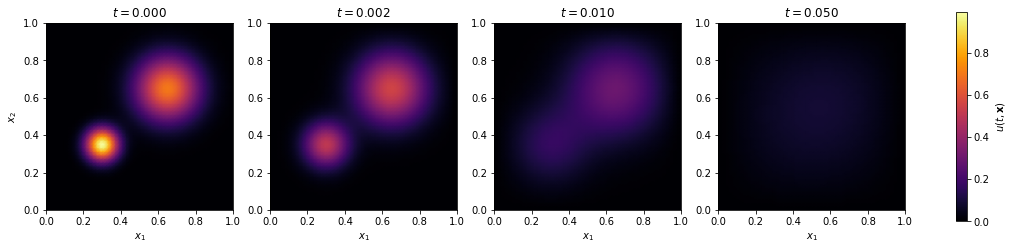

In [5]:
def with_boundary(u):
    """Embed interior values in an (N+2) x (N+2) array with zero boundary values."""
    U = np.zeros((N + 2, N + 2))
    U[1:-1, 1:-1] = u.reshape(N, N)
    return U


xb = np.linspace(0, 1, N + 2)


# four snapshots on a common color scale
snap_idx = [0, 4, 20, Nt]
vmax = U.max()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), constrained_layout=True)
for ax, k in zip(axes, snap_idx):
    im = ax.pcolormesh(xb, xb, with_boundary(U[k]), cmap="inferno",
                       vmin=0, vmax=vmax, shading="gouraud")
    ax.set_aspect("equal")
    ax.set_title(f"$t = {t[k]:.3f}$")
    ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
fig.colorbar(im, ax=axes, shrink=0.85, label="$u(t, \\mathbf{x})$")
fig.savefig("heat_2d_snapshots.png", dpi=200, bbox_inches="tight")
plt.show()

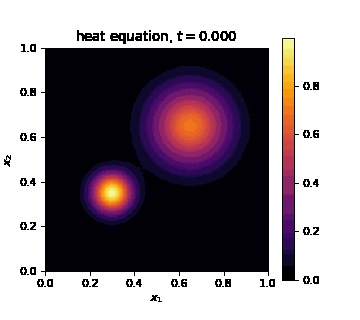

In [6]:
# animation of the evolution, saved as a gif
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.pcolormesh(xb, xb, with_boundary(U[0]), cmap="inferno",
                   vmin=0, vmax=vmax, shading="gouraud")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
fig.colorbar(im, ax=ax)
title = ax.set_title("")
frames = range(0, Nt + 1, 2)


def update(k):
    im.set_array(with_boundary(U[k]).ravel())
    title.set_text(f"heat equation, $t = {t[k]:.3f}$")
    return im, title


anim = FuncAnimation(fig, update, frames=frames, blit=False)
anim.save("heat_2d.gif", writer=PillowWriter(fps=15), dpi=80)
plt.close(fig)
Image(filename="heat_2d.gif")